# Import packages

In [1]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import fiona

import isodate
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import calendar
from pathlib import Path

# Read data

## Read nbt-related YouTube data

In [ ]:
videos_info_finland = pd.read_csv('data/videos_info_finland_all.csv')
videos_info_finland_geotagged = videos_info_finland[~videos_info_finland['latitude'].isnull()]
print(f'videos_info_finland.shape: {videos_info_finland.shape}')
print(f'videos_info_finland_geotagged.shape: {videos_info_finland_geotagged.shape}')

(195228, 32)

In [ ]:
# Read nbt_identification pickle files and combine them
data_dir = Path('.')
files = sorted(data_dir.glob('data/nbt_identification_files/nbt_identification_qwen3_14b_*.pkl'))

series_list = [pd.read_pickle(f) for f in files]
# ensure each item is a Series
series_list = [s if isinstance(s, pd.Series) else pd.Series(s) for s in series_list]

# Append series preserving original indices
nbt_identification = pd.concat(series_list, axis=0)

# Uniform the answers (case-insensitive); non-matching entries -> NA
nbt_identification = nbt_identification.astype(str).apply(
    lambda x: 'Yes' if 'yes' in x.lower() else ('No' if 'no' in x.lower() else pd.NA)
)
nbt_identification

nbt_identification.to_pickle('data/nbt_identification_qwen3_14b.pkl')

In [ ]:
# Get videos marked as 'Yes'
video_id_nbt_relevant = nbt_identification[nbt_identification['nbt_relevance']=='Yes'].videoo_id.to_list()
nbt_videos = videos_info_finland[videos_info_finland['video_id'].isin(video_id_nbt_relevant)].copy()

# Remove duplicates based on video_id
nbt_videos = nbt_videos.drop_duplicates(subset='video_id').reset_index(drop=True)

nbt_videos.shape

(33334, 32)

In [14]:
# Convert nbt_videos to GeoDataFrame
geometry = [Point(xy) for xy in zip(nbt_videos['longitude'], nbt_videos['latitude'])]

gdf_nbt_videos = gpd.GeoDataFrame(nbt_videos, geometry=geometry, crs='EPSG:4326')

gdf_nbt_videos = gdf_nbt_videos.to_crs(epsg=3067)

## Read boundaries

In [3]:
# Read Finland boundary shapefile
gdf_finland = gpd.read_file('../boundaries/Finland_shapefile/Finland_boundaries.shp')
gdf_finland.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [3]:
# Read state-owned lands boundary
gdf_state_lands = gpd.read_file('../boundaries/MH kiinteistot.gpkg')
gdf_state_lands.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: >

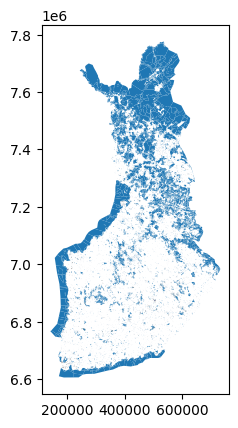

In [4]:
gdf_state_lands.plot()

In [23]:
# Read state-owned nature reserves boundary
gdf_state_nature_reserves = gpd.read_file('../boundaries/luonnonsuojelualueet_valtio/LsAlueValtio.shp')
gdf_state_nature_reserves.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [24]:
# Read national parks boundary
gdf_national_parks = gpd.read_file('../boundaries/finnish_national_parks_syke_2024.gpkg')
gdf_national_parks.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [25]:
# Read wilderness areas boundary
gdf_wilderness = gpd.read_file('../boundaries/luonnonsuojelualueet_eramaa/LsAlueEramaa.shp')
gdf_wilderness.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [5]:
# Get layers in the administrative boundaries GeoPackage
layers = fiona.listlayers('../boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg')
print(layers)

['Maakunta', 'Elinvoimakeskus', 'Valtakunta', 'Kunta', 'Hyvinvointialue']


In [2]:
# Read municipality boundaries
gdf_municipality = gpd.read_file('../boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg', layer='Kunta')
gdf_municipality.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

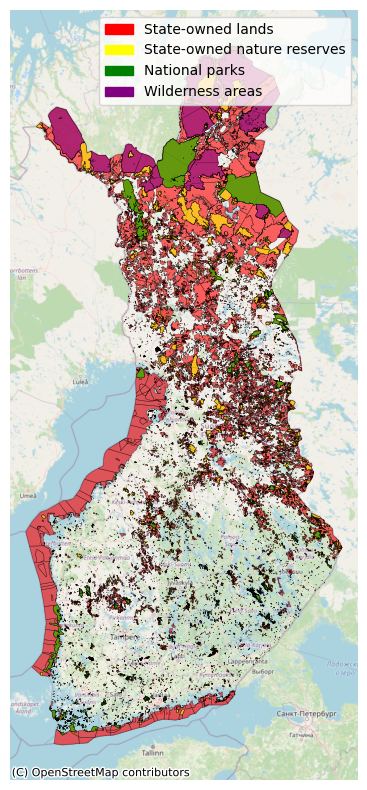

In [30]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import contextily as ctx

# Reproject to Web Mercator if needed
gdf_state_lands_web = gdf_state_lands.to_crs(epsg=3857)
gdf_state_nature_reserves_web = gdf_state_nature_reserves.to_crs(epsg=3857)
gdf_national_parks_web = gdf_national_parks.to_crs(epsg=3857)
gdf_wilderness_web = gdf_wilderness.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))

# Plot each layer
gdf_state_lands_web.plot(ax=ax, color='red', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_state_nature_reserves_web.plot(ax=ax, color='yellow', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_national_parks_web.plot(ax=ax, color='green', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_wilderness_web.plot(ax=ax, color='purple', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=gdf_state_lands_web.crs, zorder=1)

# Create legend handles
red_patch = mpatches.Patch(color='red', label='State-owned lands')
yellow_patch = mpatches.Patch(color='yellow', label='State-owned nature reserves')
green_patch = mpatches.Patch(color='green', label='National parks')
purple_patch = mpatches.Patch(color='purple', label='Wilderness areas')

ax.legend(handles=[red_patch, yellow_patch, green_patch, purple_patch],
          loc='upper right',
          frameon=True)

# ax.set_title("State-Owned Lands, State-owned Nature Reserves, and National Parks")
ax.set_axis_off()

plt.show()



## Read nbt_related YouTube data within boundaries

In [4]:
def spatial_join_videos_with_boundary(gdf_videos, gdf_boundary):
    # Perform spatial join
    gdf_joined = gpd.sjoin(gdf_videos, gdf_boundary, how='inner', predicate='within')
    # Keep only original columns
    gdf_joined = gdf_joined[gdf_videos.columns]

    return gdf_joined

In [31]:
# Spatial join: keep only points that fall within state-owned lands
gdf_videos_state = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_state_lands)

# Spatial join: keep only points that fall within state-owned nature reserves
gdf_videos_nr = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_state_nature_reserves)
# Add a column "nature_reserve" to gdf_videos_state
gdf_videos_state['nature_reserve'] = gdf_videos_state['video_id'].isin(gdf_videos_nr['video_id']).astype(int)

# Spatial join: keep only points that fall within national parks
gdf_videos_np = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_national_parks)
# Add a column "national_park" to gdf_videos_state
gdf_videos_state['national_park'] = gdf_videos_state['video_id'].isin(gdf_videos_np['video_id']).astype(int)

# Spatial join: keep only points that fall within wilderness areas
gdf_videos_wa = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_wilderness)
# Add a column "wilderness_area" to gdf_videos_state
gdf_videos_state['wilderness_area'] = gdf_videos_state['video_id'].isin(gdf_videos_wa['video_id']).astype(int)

In [ ]:
gdf_videos_state = gpd.sjoin(
    gdf_videos_state,
    gdf_municipality[["namefin", "geometry"]],
    how="left",
    predicate="within"
)

# Rename for clarity
gdf_videos_state = gdf_videos_state.rename(columns={"namefin": "municipality"})


In [43]:
gdf_videos_state['municipality'].value_counts()[:20].to_frame()

,count
municipality,
Sodankylä,2500
Inari,720
Muonio,249
Kolari,238
Lieksa,223
Pudasjärvi,172
Enontekiö,146
Kuusamo,142
Pelkosenniemi,140


In [9]:
gdf_municipality['youtube_count'] = (gdf_municipality['namefin'].map(gdf_videos_state['municipality'].value_counts()))

In [10]:
gdf_municipality['youtube_count'].max()

2500.0

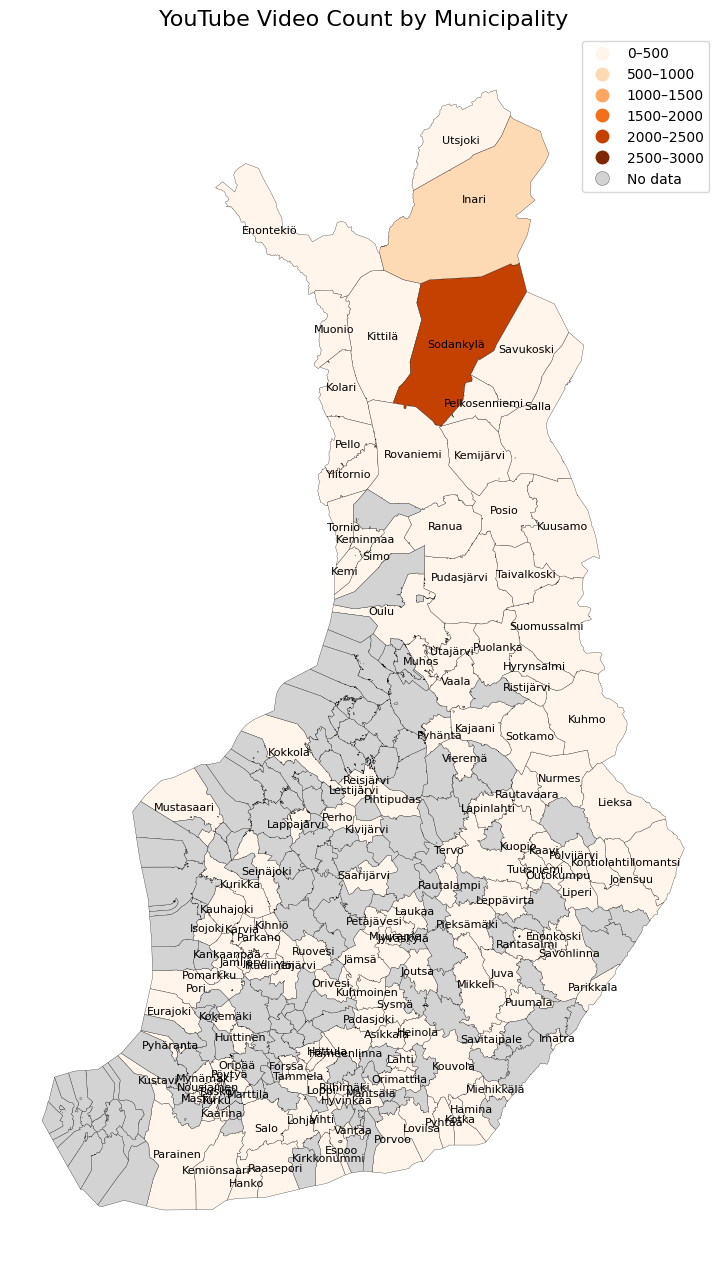

In [11]:
import matplotlib.pyplot as plt

bins = [0, 500, 1000, 1500, 2000, 2500, 3000]
labels = ["0–500", "500–1000", "1000–1500", "1500–2000", "2000–2500", "2500–3000"]

gdf_municipality["youtube_cat"] = pd.cut(gdf_municipality["youtube_count"], bins=bins, labels=labels)
                                         

fig, ax = plt.subplots(1, 1, figsize=(12, 16))

gdf_municipality.plot(
    column="youtube_cat",
    categorical=True,
    cmap="Oranges",
    legend=True,
    ax=ax,
    edgecolor="black",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "No data"}
)

# Label municipalities
# for _, row in gdf_municipality.iterrows():
#     if row.geometry is not None:
#         point = row.geometry.representative_point()
#         ax.annotate(
#             row["namefin"],
#             xy=(point.x, point.y),
#             ha="center",
#             va="center",
#             fontsize=8,
#             color="black"
#         )
for _, row in gdf_municipality.iterrows():
    if row.geometry is not None and pd.notna(row["youtube_cat"]):
        point = row.geometry.representative_point()
        ax.annotate(
            row["namefin"],
            xy=(point.x, point.y),
            ha="center",
            va="center",
            fontsize=8,
            color="black"
        )



ax.set_title("YouTube Video Count by Municipality", fontsize=16)
ax.axis("off")

plt.show()

In [32]:
def preprocess_gdf_videos(gdf_videos):
    # Drop duplicate video_id entries
    gdf_videos = gdf_videos.drop_duplicates(subset='video_id').reset_index(drop=True)
    # Select relevant columns
    gdf_videos = gdf_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title', 'published_at',
                             'location','category_id', 'topics', 'default_audio_language', 'default_language',
                             'tags', 'comment_count', 'like_count', 'view_count', 'thumbnail_default',
                             'duration', 'nature_reserve', 'national_park', 'wilderness_area', 'geometry']]

    # Get the datetime
    gdf_videos['datetime'] = pd.to_datetime(gdf_videos['published_at'], utc=True)
    gdf_videos['year'] = gdf_videos['datetime'].dt.year
    gdf_videos['month'] = gdf_videos['datetime'].dt.month
    gdf_videos['year_month'] = gdf_videos['datetime'].dt.to_period('M')

    # Convert duration from ISO 8601 to seconds
    gdf_videos['duration_seconds'] = gdf_videos['duration'].apply(lambda x: isodate.parse_duration(x).total_seconds())

    return gdf_videos

In [ ]:
# Read videos stored in Allas
df_allas = pd.read_csv('data/video_ids_allas.csv')
ls_allas = df_allas['video_id'].tolist()

# Keep only videos that are in Allas
gdf_videos_state = gdf_videos_state[gdf_videos_state['video_id'].isin(ls_allas)].copy()

In [ ]:
# Remove the video with video_id that video is not accessible anymore
gdf_videos_state = gdf_videos_state[gdf_videos_state['video_id']!= 'J1vbNisWNVQ']
gdf_videos_state = gdf_videos_state[gdf_videos_state['video_id']!= '4MX_xa_VwIc']

# Remove the video with video_id that video file is corrupt
gdf_videos_state = gdf_videos_state[gdf_videos_state['video_id']!= 'b1TYxFvPgAg']
gdf_videos_state = gdf_videos_state[gdf_videos_state['video_id']!= 'eBaqNfUnEOM']
gdf_videos_state = gdf_videos_state[gdf_videos_state['video_id']!= 'TIXTPHIRlVg']

In [ ]:
# Preprocess gdf_videos_state
gdf_videos_state = preprocess_gdf_videos(gdf_videos_state)
gdf_videos_state.to_file('data/nbt_videos_in_state_owned_lands.gpkg', driver='GPKG')

In [6]:
# Read the geopackage file of nbt_videos_in_state_owned_lands
gdf_videos_state = gpd.read_file('data/nbt_videos_in_state_owned_lands.gpkg')
gdf_videos_state.shape

(6222, 28)

In [6]:
gdf_videos_state.columns

Index(['video_id', 'title', 'description', 'channel_id', 'channel_title',
       'published_at', 'location', 'category_id', 'topics',
       'default_audio_language', 'default_language', 'tags', 'comment_count',
       'like_count', 'view_count', 'thumbnail_default', 'duration',
       'nature_reserve', 'national_park', 'wilderness_area', 'datetime',
       'year', 'month', 'year_month', 'duration_seconds', 'index_right',
       'municipality', 'geometry'],
      dtype='object')

In [8]:
gdf_videos_state.year.value_counts().sort_index()

year
2018     231
2019     407
2020    1087
2021    1399
2022    1243
2023    1858
Name: count, dtype: int64

# Explore videos

In [36]:
area = 'state-owned lands'
gdf_videos = gdf_videos_state.copy()

# area = 'state-owned nature reserves'
# gdf_videos = gdf_videos[gdf_videos['nature_reserve']==1].copy()
gdf_videos_nr = gdf_videos[gdf_videos['nature_reserve']==1].copy()

# area = 'national parks'
# gdf_videos = gdf_videos[gdf_videos['national_park']==1].copy()
gdf_videos_np = gdf_videos[gdf_videos['national_park']==1].copy()

# area = 'wilderness areas'
# gdf_videos = gdf_videos[gdf_videos['wilderness_area']==1].copy()
gdf_videos_wa = gdf_videos[gdf_videos['wilderness_area']==1].copy()

# area = 'state-owned commercial forests'
# gdf_videos = gdf_videos[(gdf_videos['nature_reserve']==0) & (gdf_videos['wilderness_area']==0)].copy()
gdf_videos_cf = gdf_videos[(gdf_videos['nature_reserve']==0) & (gdf_videos['wilderness_area']==0)].copy()

In [37]:
print(f"Number of NBT videos in state-owned nature reserves: {gdf_videos_nr.shape[0]}")
print(f"Number of NBT videos in national parks: {gdf_videos_np.shape[0]}")
print(f"Number of NBT videos in wilderness areas: {gdf_videos_wa.shape[0]}")
print(f"Number of NBT videos in state-owned commercial forests: {gdf_videos_cf.shape[0]}")

Number of NBT videos in state-owned nature reserves: 2916
Number of NBT videos in national parks: 2655
Number of NBT videos in wilderness areas: 567
Number of NBT videos in state-owned commercial forests: 2744


## Duration

In [38]:
gdf_videos['duration_minutes'] = gdf_videos['duration_seconds'].apply(lambda x: x / 60)

print(gdf_videos['duration_minutes'].describe())
print(f"Total duration: {gdf_videos['duration_minutes'].sum():.2f} minutes")

count    6227.000000
mean       10.573556
std        21.261471
min         0.066667
25%         1.383333
50%         4.233333
75%        13.050000
max       714.966667
Name: duration_minutes, dtype: float64
Total duration: 65841.53 minutes


## Temporal patterns

### State-owned lands

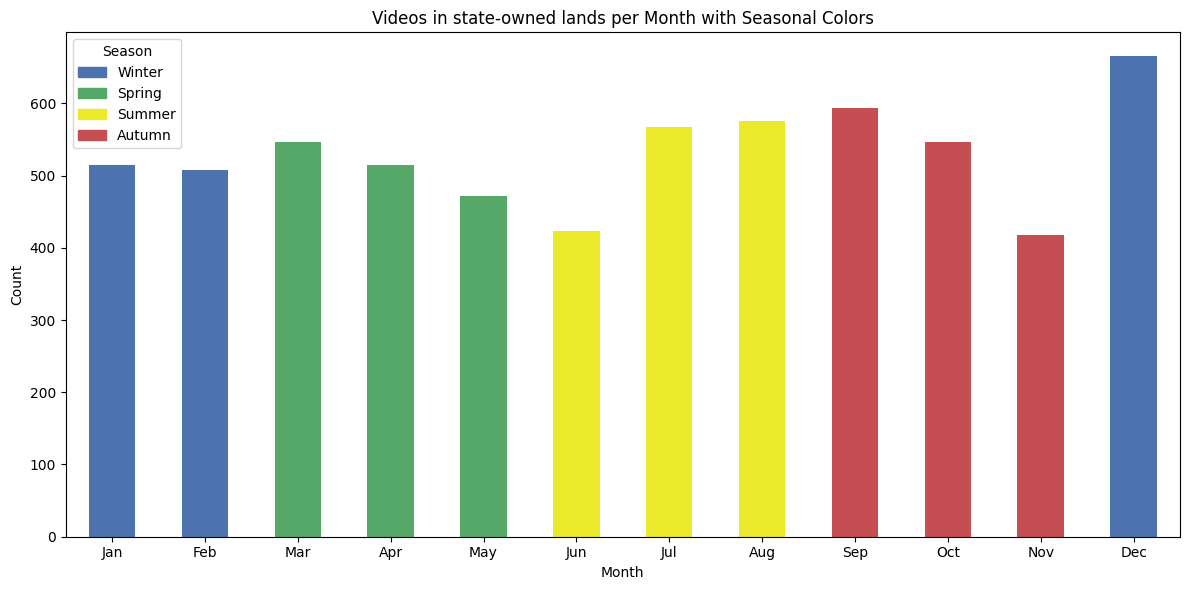

In [ ]:
# Plot number of videos per month with seasonal colors
counts = gdf_videos.month.value_counts().sort_index()

def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[month_to_season(m)] for m in counts.index]

ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Month')
ax.set_ylabel('Count')
ax.set_xticklabels([calendar.month_abbr[m] for m in counts.index], rotation=0)
ax.set_title(f'Videos in {area} per Month with Seasonal Colors')
plt.tight_layout()
plt.show()

<Axes: title={'center': 'Videos in state-owned lands'}, xlabel='year'>

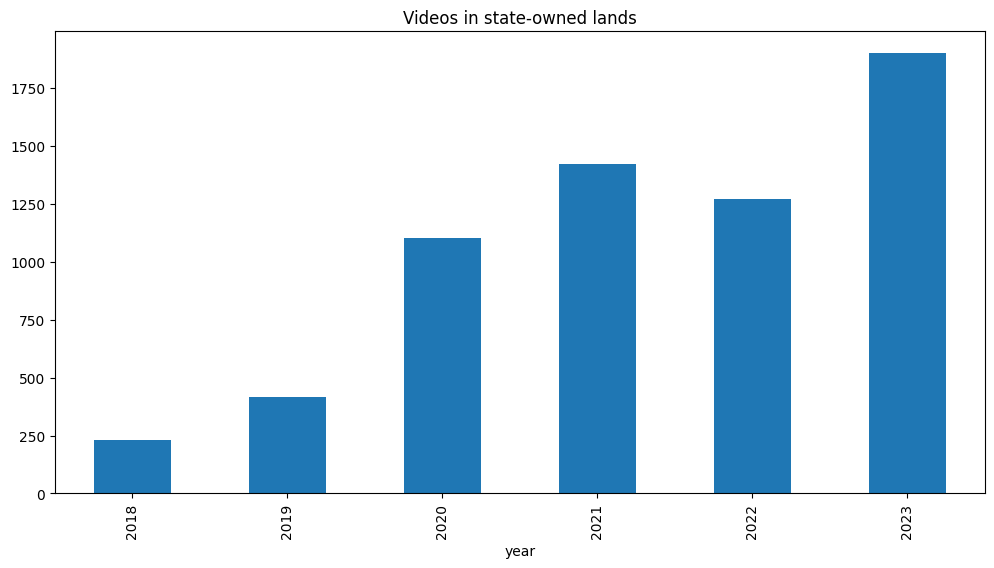

In [27]:
# Plot number of videos per year
gdf_videos.year.value_counts().sort_index().plot(kind='bar', figsize=(12,6), title=f'Videos in {area}')

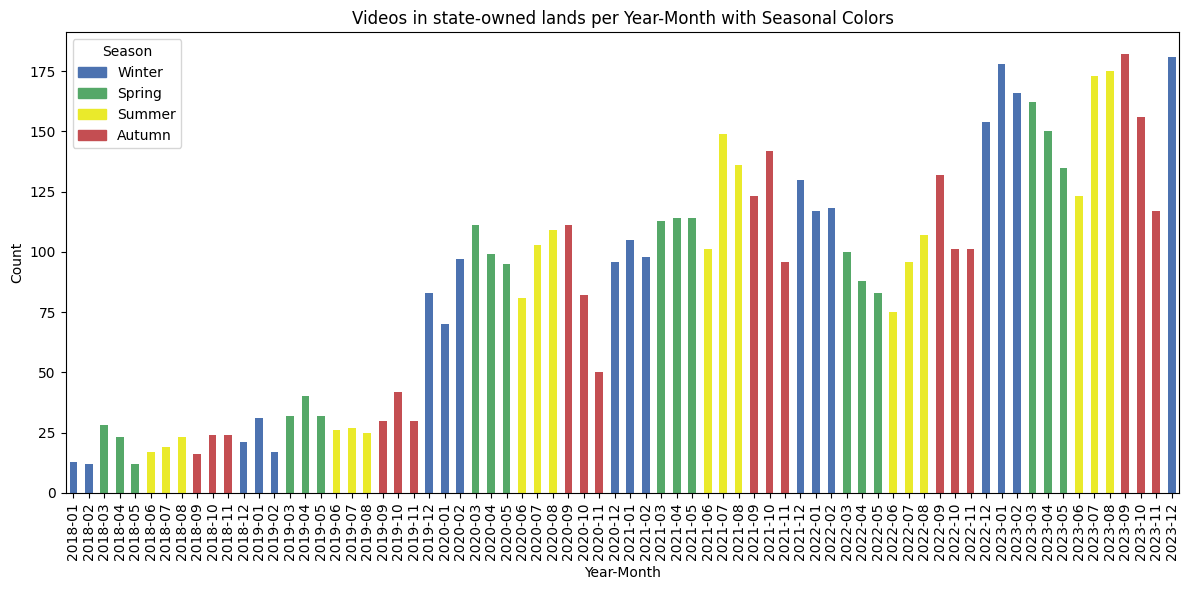

In [28]:
# Plot number of videos per year-month with seasonal colors
counts = gdf_videos.year_month.value_counts().sort_index()

# get month numbers from PeriodIndex
counts.index = pd.PeriodIndex(counts.index, freq="M")
months = counts.index.month

# map month -> season
def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

seasons = [month_to_season(m) for m in months]

# color palette for seasons
palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[s] for s in seasons]

# plot with seasonal colors and legend
ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Count')
ax.set_title(f'Videos in {area} per Year-Month with Seasonal Colors')
plt.tight_layout()
plt.show()

### State-owned nature reserves

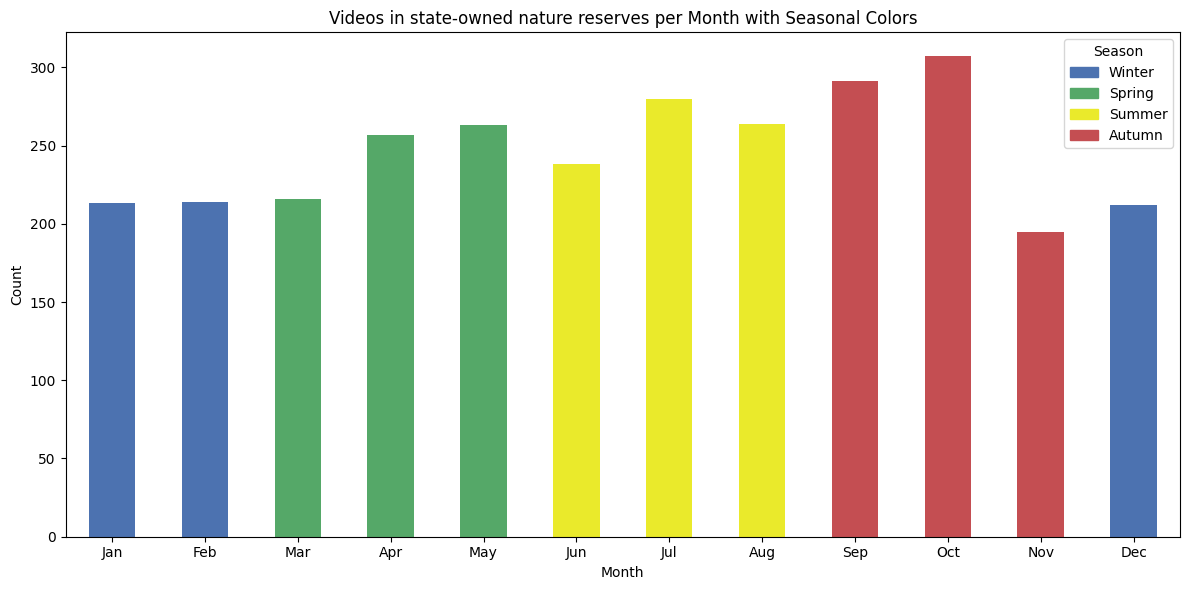

In [ ]:
# Plot number of videos per month with seasonal colors
counts = gdf_videos.month.value_counts().sort_index()

def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[month_to_season(m)] for m in counts.index]

ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Month')
ax.set_ylabel('Count')
ax.set_xticklabels([calendar.month_abbr[m] for m in counts.index], rotation=0)
ax.set_title(f'Videos in {area} per Month with Seasonal Colors')
plt.tight_layout()
plt.show()

<Axes: title={'center': 'Videos in state-owned nature reserves'}, xlabel='year'>

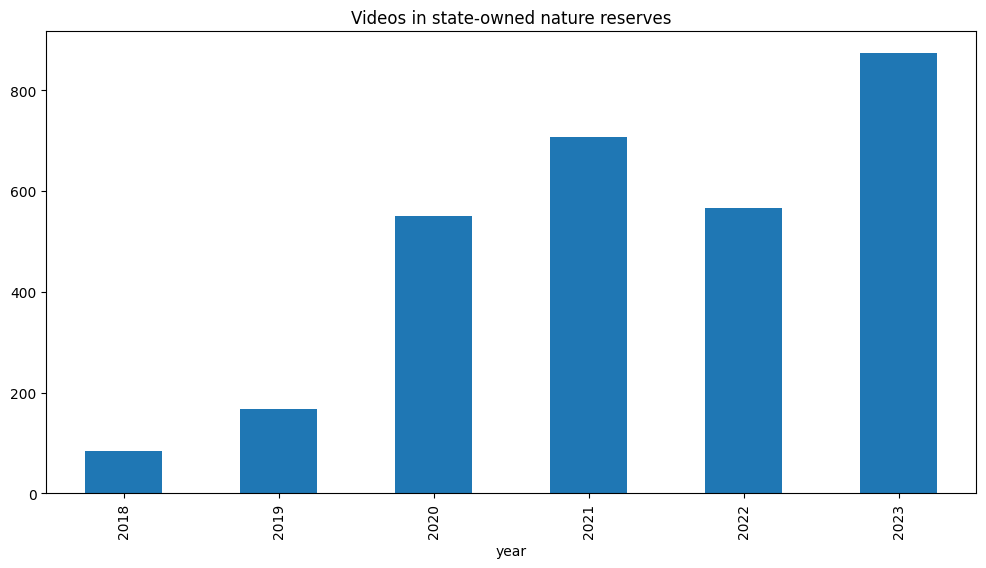

In [31]:
# Plot number of videos per year
gdf_videos.year.value_counts().sort_index().plot(kind='bar', figsize=(12,6), title=f'Videos in {area}')

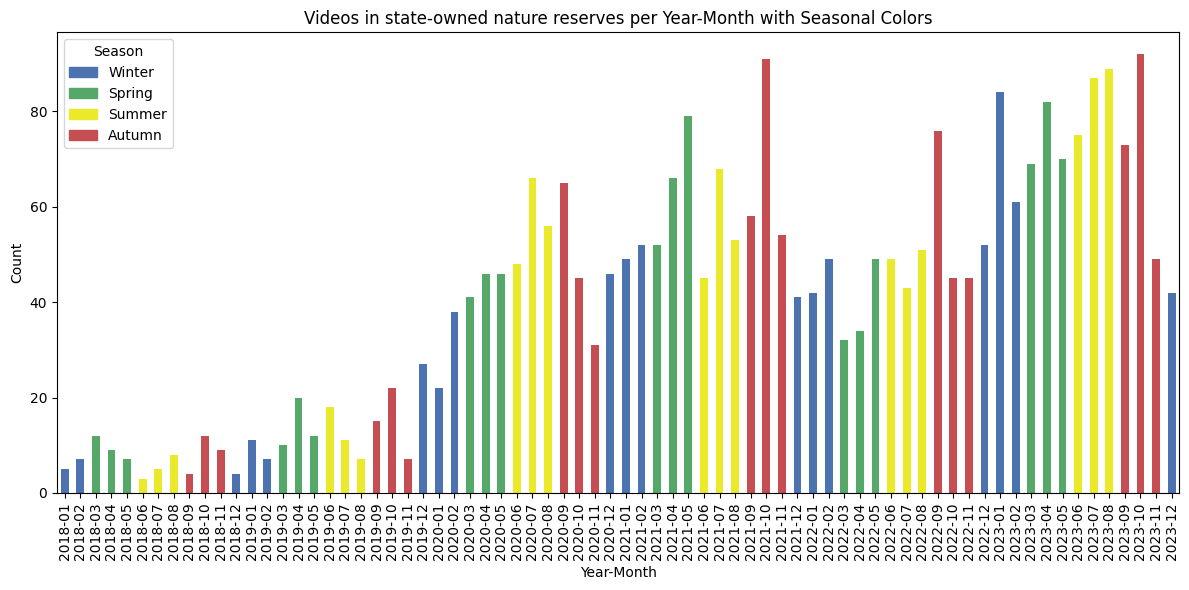

In [32]:
# Plot number of videos per year-month with seasonal colors
counts = gdf_videos.year_month.value_counts().sort_index()

# get month numbers from PeriodIndex
counts.index = pd.PeriodIndex(counts.index, freq="M")
months = counts.index.month

# map month -> season
def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

seasons = [month_to_season(m) for m in months]

# color palette for seasons
palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[s] for s in seasons]

# plot with seasonal colors and legend
ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Count')
ax.set_title(f'Videos in {area} per Year-Month with Seasonal Colors')
plt.tight_layout()
plt.show()

### National parks

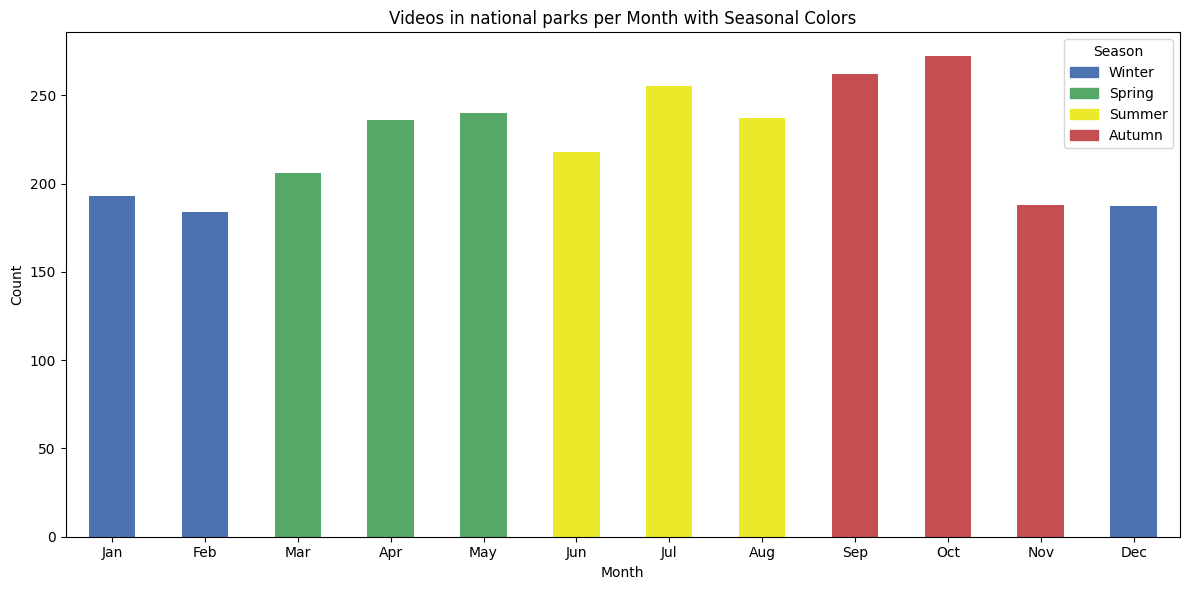

In [ ]:
# Plot number of videos per month with seasonal colors
counts = gdf_videos.month.value_counts().sort_index()

def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[month_to_season(m)] for m in counts.index]

ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Month')
ax.set_ylabel('Count')
ax.set_xticklabels([calendar.month_abbr[m] for m in counts.index], rotation=0)
ax.set_title(f'Videos in {area} per Month with Seasonal Colors')
plt.tight_layout()
plt.show()

<Axes: title={'center': 'Videos in national parks'}, xlabel='year'>

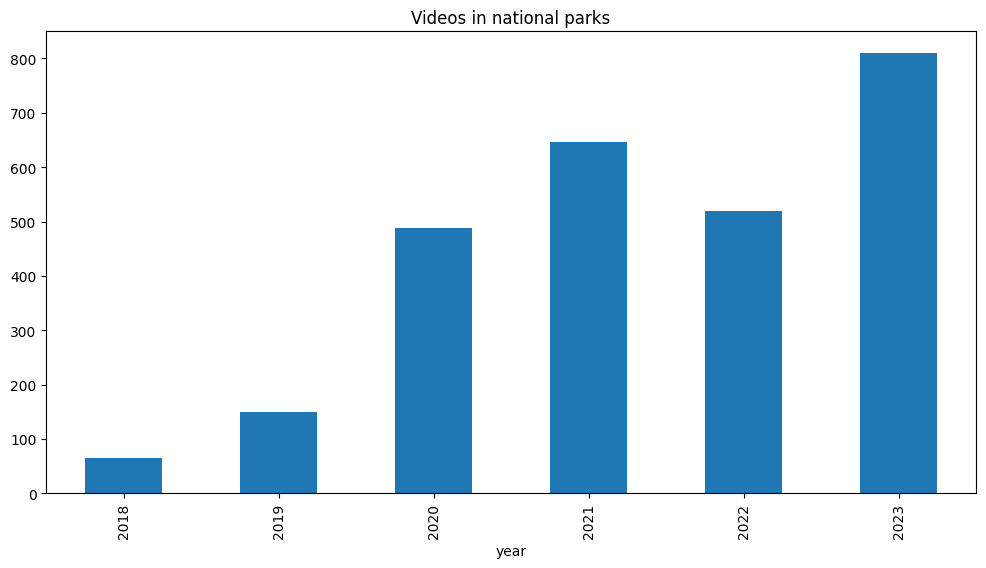

In [ ]:
# Plot number of videos per year
gdf_videos.year.value_counts().sort_index().plot(kind='bar', figsize=(12,6), title=f'Videos in {area}')

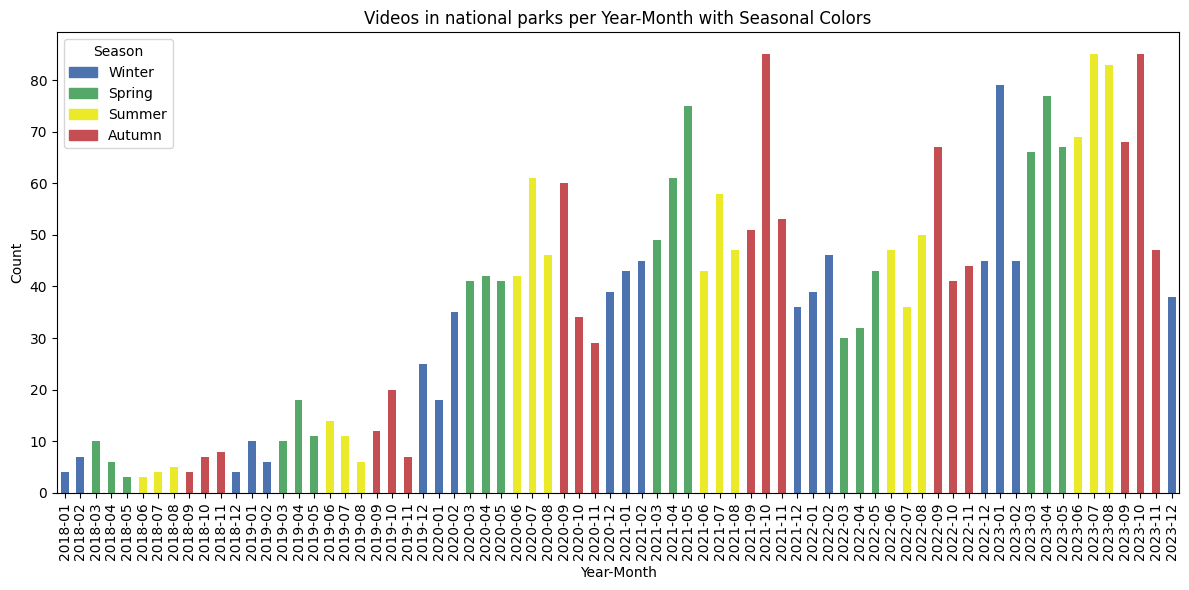

In [ ]:
# National parks
# Plot number of videos per year-month with seasonal colors
counts = gdf_videos.year_month.value_counts().sort_index()

# get month numbers from PeriodIndex
counts.index = pd.PeriodIndex(counts.index, freq="M")
months = counts.index.month

# map month -> season
def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

seasons = [month_to_season(m) for m in months]

# color palette for seasons
palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[s] for s in seasons]

# plot with seasonal colors and legend
ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Count')
ax.set_title(f'Videos in {area} per Year-Month with Seasonal Colors')
plt.tight_layout()
plt.show()

### Wilderness areas

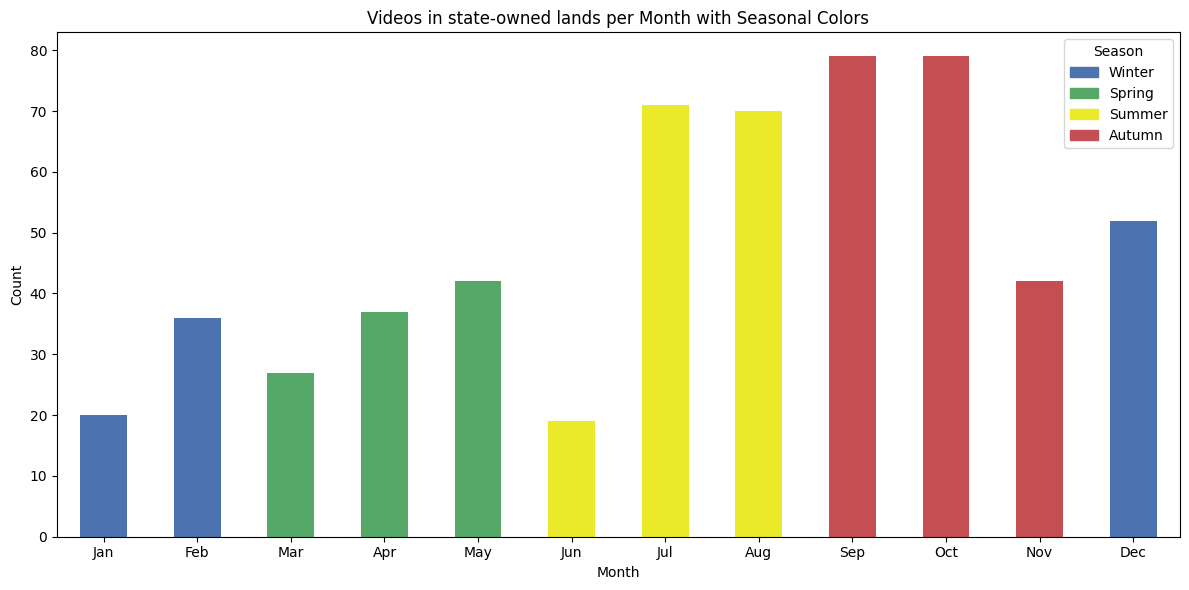

In [52]:
# Plot number of videos per month with seasonal colors
counts = gdf_videos.month.value_counts().sort_index()

def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[month_to_season(m)] for m in counts.index]

ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Month')
ax.set_ylabel('Count')
ax.set_xticklabels([calendar.month_abbr[m] for m in counts.index], rotation=0)
ax.set_title(f'Videos in {area} per Month with Seasonal Colors')
plt.tight_layout()
plt.show()

<Axes: title={'center': 'Videos in state-owned lands'}, xlabel='year'>

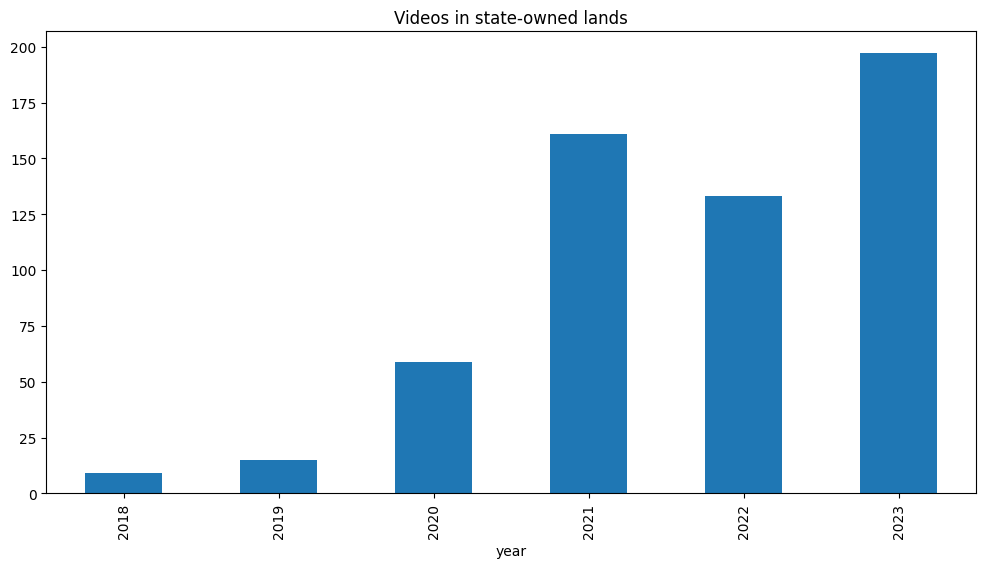

In [53]:
# Plot number of videos per year
gdf_videos.year.value_counts().sort_index().plot(kind='bar', figsize=(12,6), title=f'Videos in {area}')

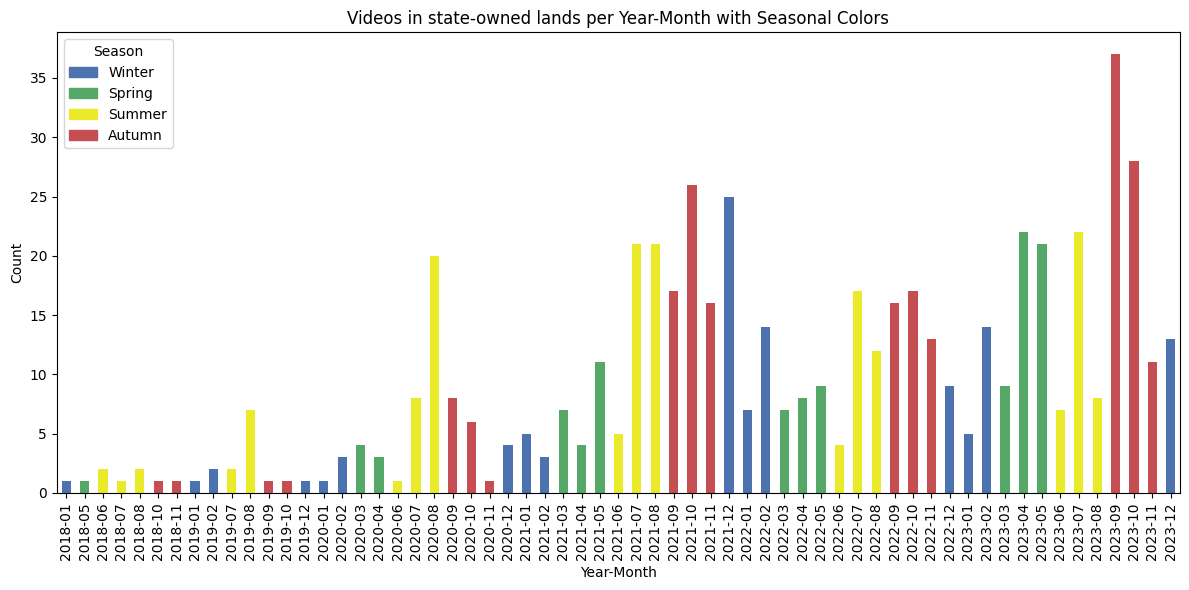

In [54]:
# Plot number of videos per year-month with seasonal colors
counts = gdf_videos.year_month.value_counts().sort_index()

# get month numbers from PeriodIndex
counts.index = pd.PeriodIndex(counts.index, freq="M")
months = counts.index.month

# map month -> season
def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

seasons = [month_to_season(m) for m in months]

# color palette for seasons
palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[s] for s in seasons]

# plot with seasonal colors and legend
ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Count')
ax.set_title(f'Videos in {area} per Year-Month with Seasonal Colors')
plt.tight_layout()
plt.show()

### State-owned commercial forests

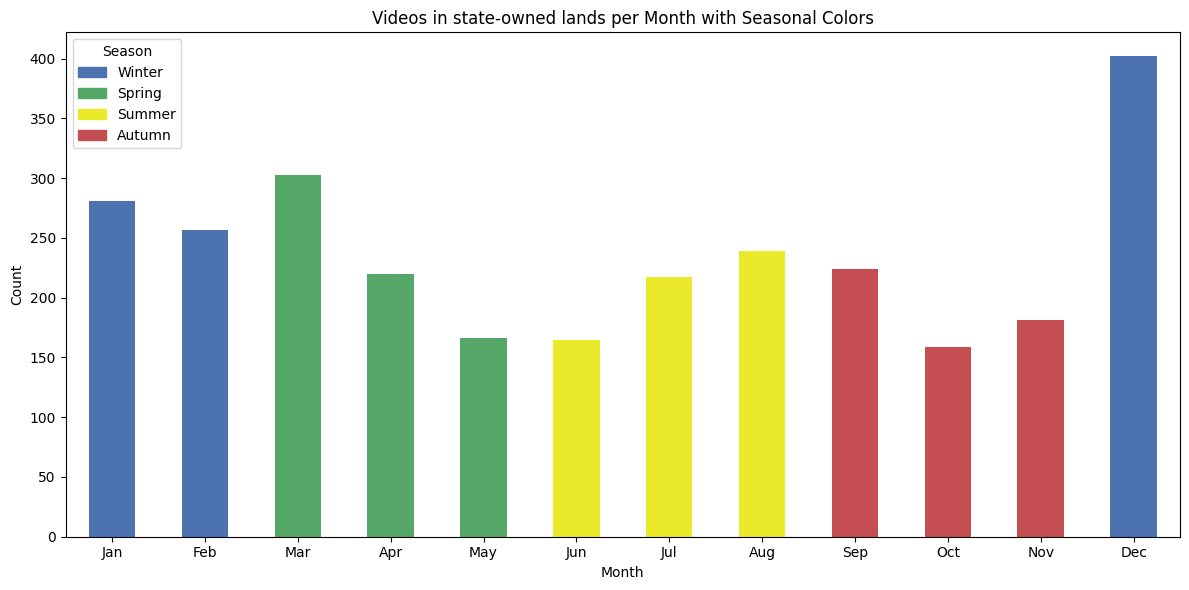

In [47]:
# Plot number of videos per month with seasonal colors
counts = gdf_videos.month.value_counts().sort_index()

def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[month_to_season(m)] for m in counts.index]

ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Month')
ax.set_ylabel('Count')
ax.set_xticklabels([calendar.month_abbr[m] for m in counts.index], rotation=0)
ax.set_title(f'Videos in {area} per Month with Seasonal Colors')
plt.tight_layout()
plt.show()

<Axes: title={'center': 'Videos in state-owned lands'}, xlabel='year'>

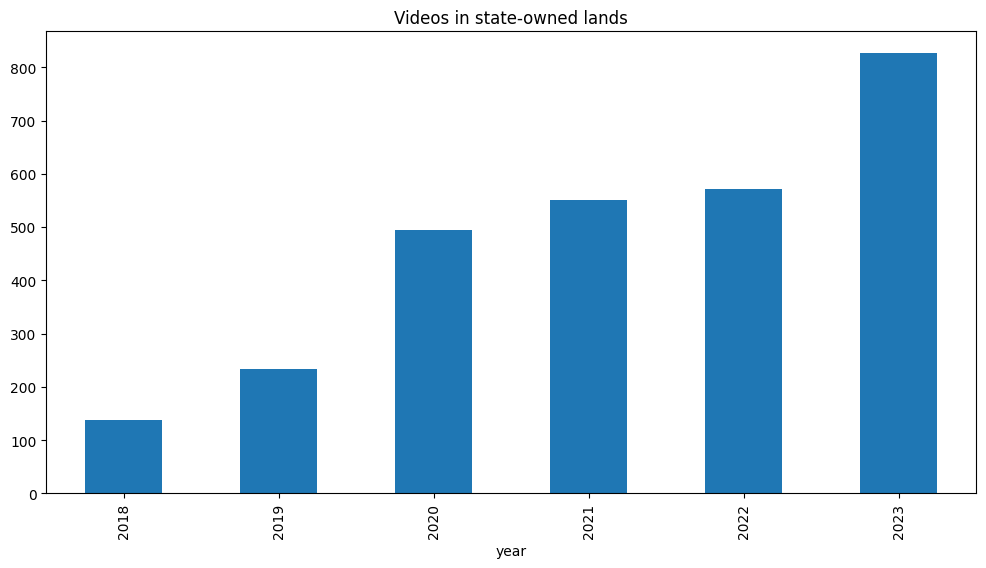

In [48]:
# Plot number of videos per year
gdf_videos.year.value_counts().sort_index().plot(kind='bar', figsize=(12,6), title=f'Videos in {area}')

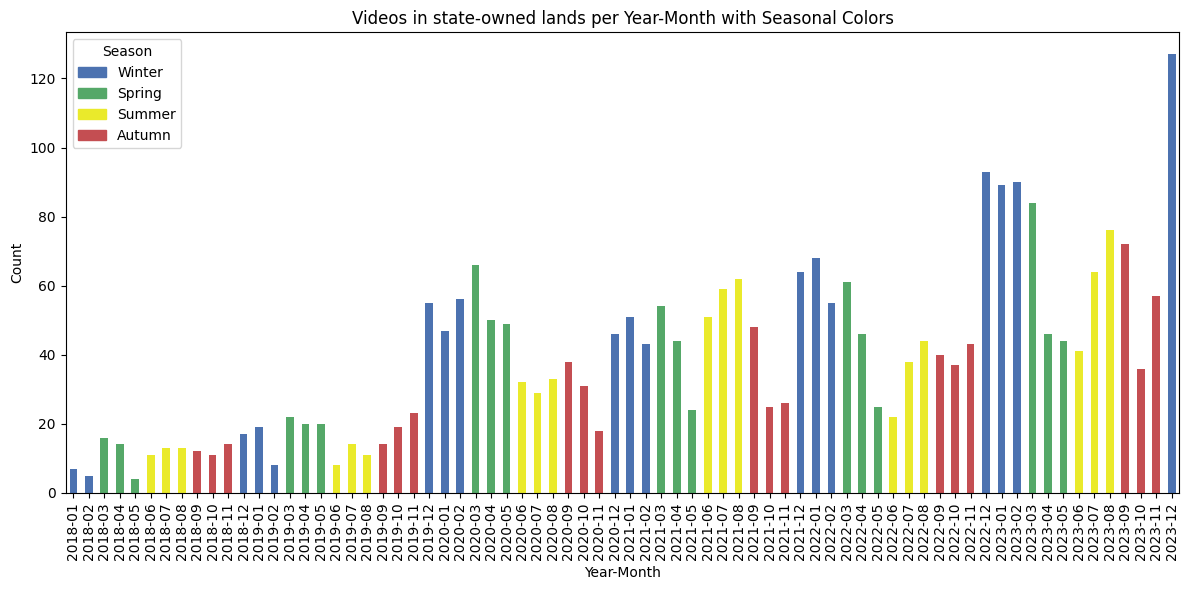

In [49]:
# Plot number of videos per year-month with seasonal colors
counts = gdf_videos.year_month.value_counts().sort_index()

# get month numbers from PeriodIndex
counts.index = pd.PeriodIndex(counts.index, freq="M")
months = counts.index.month

# map month -> season
def month_to_season(m):
    if m in (12, 1, 2):
        return 'Winter'
    if m in (3, 4, 5):
        return 'Spring'
    if m in (6, 7, 8):
        return 'Summer'
    return 'Autumn'

seasons = [month_to_season(m) for m in months]

# color palette for seasons
palette = {'Winter': '#4C72B0', 'Spring': '#55A868', 'Summer': '#EAEA2B', 'Autumn': '#C44E52'}
colors = [palette[s] for s in seasons]

# plot with seasonal colors and legend
ax = counts.plot(kind='bar', figsize=(12,6), color=colors)
import matplotlib.patches as mpatches
patches = [mpatches.Patch(color=palette[k], label=k) for k in palette]
ax.legend(handles=patches, title='Season')
ax.set_xlabel('Year-Month')
ax.set_ylabel('Count')
ax.set_title(f'Videos in {area} per Year-Month with Seasonal Colors')
plt.tight_layout()
plt.show()

## Spatial patterns

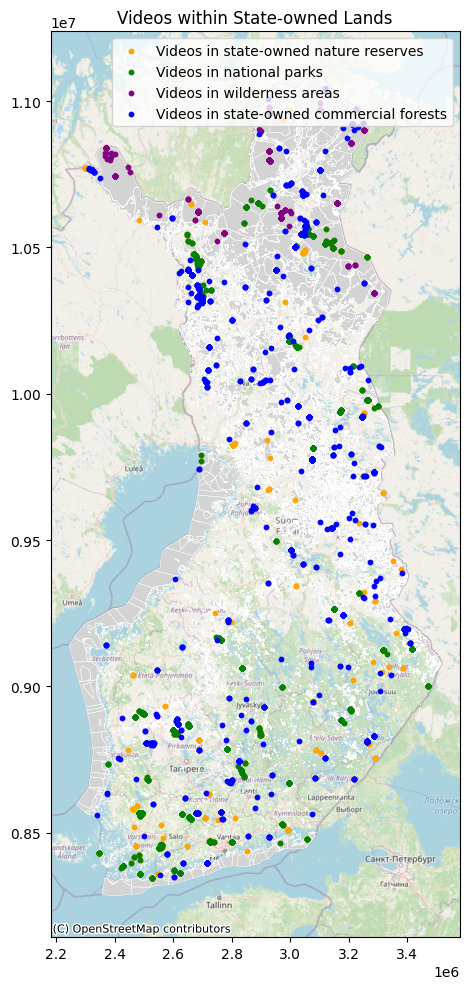

In [28]:
import contextily as ctx

# Reproject both layers to Web Mercator
gdf_state_lands_web = gdf_state_lands.to_crs(epsg=3857)
# gdf_videos_web = gdf_videos.to_crs(epsg=3857)
gdf_videos_nr_web = gdf_videos_nr.to_crs(epsg=3857)
gdf_videos_np_web = gdf_videos_np.to_crs(epsg=3857)
gdf_videos_wa_web = gdf_videos_wa.to_crs(epsg=3857)
gdf_videos_cf_web = gdf_videos_cf.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))
gdf_state_lands_web.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.4, zorder=2)
# gdf_videos_web.plot(ax=ax, color='red', markersize=10, zorder=3, label='Videos in state-owned lands')
gdf_videos_nr_web.plot(ax=ax, color='orange', markersize=10, zorder=3, label='Videos in state-owned nature reserves')
gdf_videos_np_web.plot(ax=ax, color='green', markersize=10, zorder=3, label='Videos in national parks')
gdf_videos_wa_web.plot(ax=ax, color='purple', markersize=10, zorder=3, label='Videos in wilderness areas')
gdf_videos_cf_web.plot(ax=ax, color='blue', markersize=10, zorder=3, label='Videos in state-owned commercial forests')

# add basemap underneath (ensure zorder < plotted layers)
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=gdf_state_lands_web.crs, zorder=1)

# zoom to combined bounds with a 5% margin
minx, miny, maxx, maxy = gdf_state_lands_web.total_bounds
dx = (maxx - minx) * 0.05
dy = (maxy - miny) * 0.05
ax.set_xlim(minx - dx, maxx + dx)
ax.set_ylim(miny - dy, maxy + dy)

ax.set_title("Videos within State-owned Lands")
ax.legend()
plt.tight_layout()
plt.show()

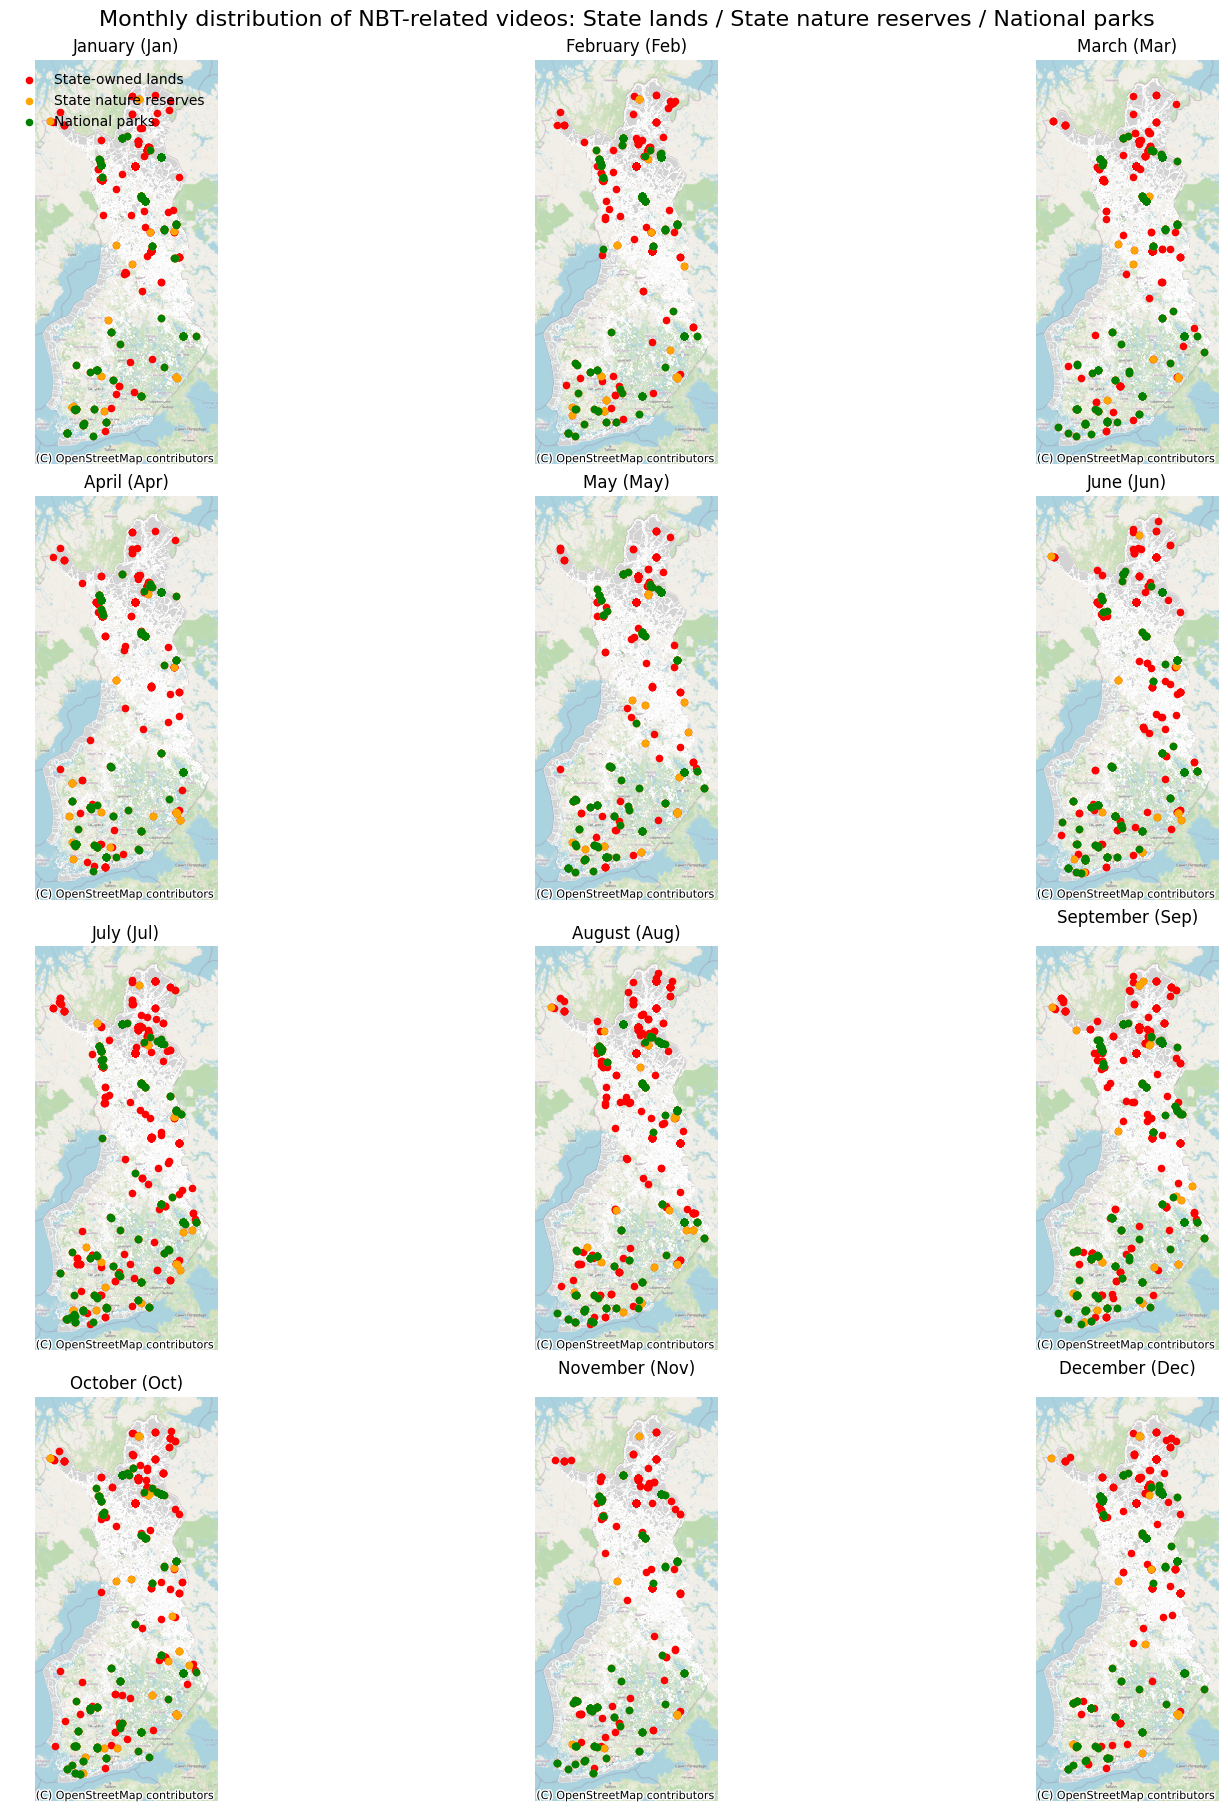

In [ ]:
import contextily as ctx

# Reproject layers to Web Mercator (repeat to ensure variables exist in this cell)
state_web = gdf_state_lands.to_crs(epsg=3857)
points_state_lands_web = gdf_videos_state.to_crs(epsg=3857)
points_state_nature_reserves_web = gdf_videos_nr.to_crs(epsg=3857)
points_national_parks_web = gdf_videos_np.to_crs(epsg=3857)

# Ensure each points GeoDataFrame has a 'month' column
def ensure_month(gdf):
    if 'month' in gdf.columns:
        return gdf
    if 'datetime' in gdf.columns:
        gdf['month'] = gdf['datetime'].dt.month
    else:
        gdf['month'] = pd.to_datetime(gdf['published_at'], utc=True).dt.month
    return gdf

points_state_lands_web = ensure_month(points_state_lands_web)
points_state_nature_reserves_web = ensure_month(points_state_nature_reserves_web)
points_national_parks_web = ensure_month(points_national_parks_web)

# Common map bounds with small margin
minx, miny, maxx, maxy = state_web.total_bounds
dx = (maxx - minx) * 0.05
dy = (maxy - miny) * 0.05
xlim = (minx - dx, maxx + dx)
ylim = (miny - dy, maxy + dy)

# Create monthly subplots (4 rows x 3 cols)
months = range(1, 13)
fig, axes = plt.subplots(4, 3, figsize=(15, 18), constrained_layout=True)
axes = axes.flatten()

colors = {
    'state_lands': 'red',
    'state_nature': 'orange',
    'national_parks': 'green'
}

for i, m in enumerate(months):
    ax = axes[i]
    # plot base polygons
    state_web.plot(ax=ax, color='lightgrey', edgecolor='white', linewidth=0.3, zorder=2)
    # filter points by month
    pts_state = points_state_lands_web[points_state_lands_web['month'] == m]
    pts_state_nr = points_state_nature_reserves_web[points_state_nature_reserves_web['month'] == m]
    pts_np = points_national_parks_web[points_national_parks_web['month'] == m]
    # plot points
    if not pts_state.empty:
        pts_state.plot(ax=ax, color=colors['state_lands'], markersize=20, zorder=4, label='State-owned lands')
    if not pts_state_nr.empty:
        pts_state_nr.plot(ax=ax, color=colors['state_nature'], markersize=20, zorder=5, label='State nature reserves')
    if not pts_np.empty:
        pts_np.plot(ax=ax, color=colors['national_parks'], markersize=20, zorder=6, label='National parks')
    # basemap
    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=state_web.crs, zorder=1)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_title(f"{calendar.month_name[m]} ({calendar.month_abbr[m]})")
    ax.set_axis_off()
    # show legend only on first subplot to avoid clutter
    if i == 0:
        ax.legend(loc='upper right', frameon=False)

# remove any empty axes (if any)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Monthly distribution of NBT-related videos: State-owned lands / State-owned nature reserves / National parks", fontsize=16)
plt.show()

## Video information

In [43]:
gdf_videos.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 6330 entries, 0 to 6329
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   video_id                6330 non-null   object             
 1   title                   6330 non-null   object             
 2   description             6126 non-null   object             
 3   channel_id              6330 non-null   object             
 4   channel_title           6330 non-null   object             
 5   published_at            6330 non-null   object             
 6   location                6321 non-null   object             
 7   category_id             6330 non-null   int64              
 8   topics                  6228 non-null   object             
 9   default_audio_language  4083 non-null   object             
 10  default_language        1935 non-null   object             
 11  tags                    4864 non-nu

In [ ]:
gdf_videos[['like_count', 'view_count', 'comment_count', 'duration_seconds']].describe()

,like_count,view_count,comment_count,duration_seconds
count,6256.000000,6.342000e+03,6248.000000,6342.000000
mean,113.123721,6.360216e+03,11.556018,639.119836
std,1668.249689,1.616188e+05,63.564606,1350.082605
min,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,9.100000e+01,0.000000,83.000000
50%,7.000000,2.720000e+02,1.000000,253.500000
75%,25.000000,1.128750e+03,5.000000,781.750000
max,96216.000000,1.147338e+07,2554.000000,42898.000000


## Prolific users

In [144]:
# Count videos by channel
gdf_videos.channel_id.value_counts()

channel_id
UCrJygwIZvCQXOgYrwNlkqxA    870
UC5pIVp6uyAi7pbWXDySyQMw    136
UC16NdAq6BIn7fy7sX2JTWzw    109
UCZ2GLsGoD9oqvBClzeseqKg     98
UC85VQX9eoPsZer1Vqq9O42w     58
                           ... 
UCYpw_h7knNRylNzquW-_ong      1
UCfGAVgh7G0miMZI5n3ETIMQ      1
UCY-OaW9tQkqtcbU_Dw_v-tw      1
UCFpmdUOy0uIR6wZUGawqpww      1
UCe2H2IVxPUkFBfubaj2mEBA      1
Name: count, Length: 2443, dtype: int64

In [151]:
gdf_videos[gdf_videos.channel_id=='UCfGAVgh7G0miMZI5n3ETIMQ'][['video_id', 'title', 'channel_title', 'location', 'nature_reserve', 'national_park']]

,video_id,title,channel_title,location,nature_reserve,national_park
2591,tWQmSeap2uA,Retkiluistelua Jääluolalle Inarijärvellä 4.12....,Ulkoilma Akatemia,Inarijärvi,0,0


## User age

## User gender

In [ ]:
# Female, male, group(couple, family with kids, friends), unknown


## Popular (duplicated) locations

In [ ]:
gdf_videos.location.value_counts()

location
Urho Kekkosen kansallispuisto           832
Lapland                                 829
Hammastunturin erämaa-alue              239
Lappi                                   144
Iso-Syöte                               118
                                       ... 
Koli Relax Spa                            1
Jämijärvi Airfield                        1
Siikaneva Wetlands Conservation Area      1
Kirkas-Soljanen                           1
Jouhteninen                               1
Name: count, Length: 791, dtype: int64

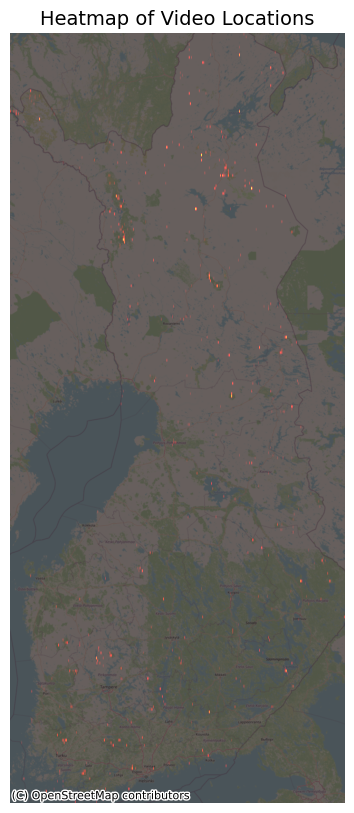

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
from shapely.geometry import Point


# Convert to Web Mercator for contextily basemap
gdf_videos_web = gdf_videos.to_crs(epsg=3857)

# --- Compute heatmap with 2D histogram ---
xmin, ymin, xmax, ymax = gdf_videos_web.total_bounds
x = gdf_videos_web.geometry.x
y = gdf_videos_web.geometry.y

# Define heatmap resolution (increase bins for smoother results)
bins = 300
heatmap, xedges, yedges = np.histogram2d(x, y, bins=bins, range=[[xmin, xmax], [ymin, ymax]])

# Plot heatmap
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(
    np.log1p(heatmap.T),  # log for better contrast
    extent=[xmin, xmax, ymin, ymax],
    origin='lower',
    cmap='hot',
    alpha=0.6,
    zorder=2
)

# Add the basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=state_web.crs, zorder=1)

ax.set_axis_off()
plt.title("Heatmap of Video Locations", fontsize=14)
plt.show()


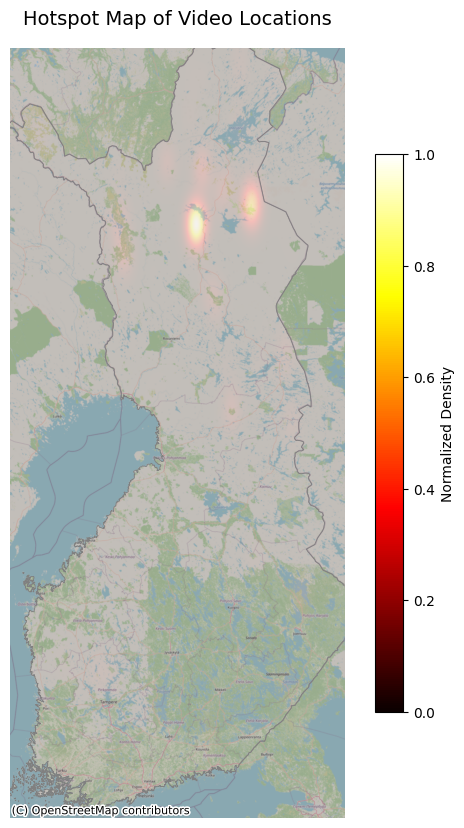

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
from scipy.ndimage import gaussian_filter

# --- Clean input ---
gdf_videos = gdf_videos[gdf_videos.geometry.notnull() & gdf_videos.is_valid]
gdf_videos = gdf_videos[gdf_videos.geometry.type == "Point"]

# --- Ensure CRS ---
if gdf_videos.crs is None:
    gdf_videos = gdf_videos.set_crs(4326, allow_override=True)
gdf_videos_web = gdf_videos.to_crs(epsg=3857)

if gdf_finland.crs is None:
    gdf_finland = gdf_finland.set_crs(4326, allow_override=True)
finland_web = gdf_finland.to_crs(epsg=3857)


# --- Extract coords ---
x = gdf_videos_web.geometry.x.values
y = gdf_videos_web.geometry.y.values
xmin, ymin, xmax, ymax = gdf_videos_web.total_bounds

# --- Build 2D histogram ---
bins = 400
heatmap, xedges, yedges = np.histogram2d(x, y, bins=bins, range=[[xmin, xmax], [ymin, ymax]])
heatmap_smooth = gaussian_filter(heatmap, sigma=8)
heatmap_smooth = heatmap_smooth / heatmap_smooth.max()  # normalize 0–1

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 10))


# Add heatmap on top
im = ax.imshow(
    heatmap_smooth.T,
    extent=[xmin, xmax, ymin, ymax],
    origin='lower',
    cmap='hot',
    alpha=1,
    vmin=0, vmax=1,
    zorder=1
)

# Add basemap under everything
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=finland_web.crs, zorder=2, alpha=0.6)
# Plot Finland boundary on top of basemap
finland_web.plot(ax=ax, facecolor='none', edgecolor='grey', linewidth=0.6, zorder=3)

# Add the basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=gdf_videos_web.crs, zorder=2, alpha=0.5)

# Force plot extent to match data
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

# Optional colorbar for debugging
plt.colorbar(im, ax=ax, fraction=0.036, pad=0.04, label='Normalized Density')

ax.set_axis_off()
plt.title("Hotspot Map of Video Locations", fontsize=14)
plt.show()


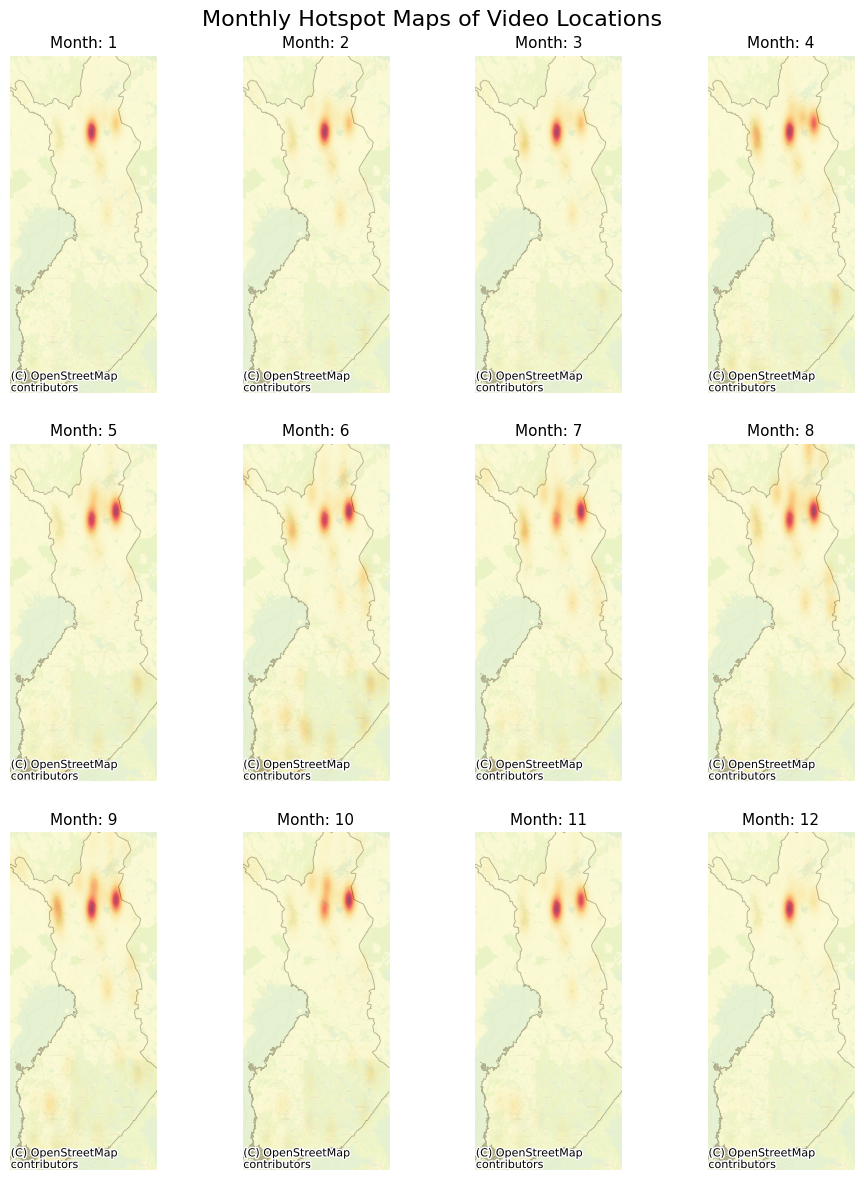

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import contextily as ctx
from scipy.ndimage import gaussian_filter

# --- Clean input ---
gdf_videos = gdf_videos[gdf_videos.geometry.notnull() & gdf_videos.is_valid]
gdf_videos = gdf_videos[gdf_videos.geometry.type == "Point"]

# --- Ensure CRS ---
if gdf_videos.crs is None:
    gdf_videos = gdf_videos.set_crs(4326, allow_override=True)
gdf_videos_web = gdf_videos.to_crs(epsg=3857)

if gdf_finland.crs is None:
    gdf_finland = gdf_finland.set_crs(4326, allow_override=True)
finland_web = gdf_finland.to_crs(epsg=3857)

# --- Compute common extent for all subplots ---
xmin, ymin, xmax, ymax = gdf_videos_web.total_bounds
bins = 300  # adjust resolution if needed

# --- Prepare figure ---
months = sorted(gdf_videos_web["month"].unique())
n_months = len(months)
ncols = 4
nrows = int(np.ceil(n_months / ncols))

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(10, 12))
axes = axes.flatten()

plt.subplots_adjust(
    wspace=0.1,  # space between columns (default ~0.2–0.3)
    hspace=0.1   # space between rows
)

for i, month in enumerate(months):
    ax = axes[i]
    gdf_month = gdf_videos_web[gdf_videos_web["month"] == month]

    # Skip empty months
    if gdf_month.empty:
        ax.set_visible(False)
        continue

    # Extract coordinates
    x = gdf_month.geometry.x.values
    y = gdf_month.geometry.y.values

    # Compute 2D histogram
    heatmap, xedges, yedges = np.histogram2d(x, y, bins=bins, range=[[xmin, xmax], [ymin, ymax]])
    heatmap_smooth = gaussian_filter(heatmap, sigma=8)
    if heatmap_smooth.max() > 0:
        heatmap_smooth = heatmap_smooth / heatmap_smooth.max()


    # Heatmap overlay
    ax.imshow(
        heatmap_smooth.T,
        extent=[xmin, xmax, ymin, ymax],
        origin='lower',
        cmap='YlOrRd',
        alpha=0.7,
        vmin=0, vmax=1,
        zorder=3
    )

    # Add basemap under everything
    ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=finland_web.crs, zorder=1)
    # Plot Finland boundary on top of basemap
    finland_web.plot(ax=ax, facecolor='none', edgecolor='black', linewidth=0.6, zorder=2)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_axis_off()
    ax.set_title(f"Month: {month}", fontsize=11)

# Remove any unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Monthly Hotspot Maps of Video Locations", fontsize=16)
plt.tight_layout()
plt.show()


In [165]:
# Count videos by unique geometry points
geometry_counts = gdf_videos.geometry.value_counts()
geometry_counts

geometry
POINT (479222.434 7534276.952)    1381
POINT (551876.926 7561971.665)     845
POINT (487077.394 7606624.83)      223
POINT (443035.188 7614738.548)     145
POINT (506512.417 7432936.22)      104
                                  ... 
POINT (245694.995 6743667.991)       1
POINT (250079.828 6741051.278)       1
POINT (376535.996 6724693.999)       1
POINT (621726.439 6854021.007)       1
POINT (640484.917 6965325.592)       1
Name: count, Length: 782, dtype: int64

In [ ]:
# Sort gdf_videos by frequency of geometry points
gdf_videos_sorted = (gdf_videos
                     .assign(geometry_counts=gdf_videos.geometry.map(geometry_counts))
                     .sort_values(by='geometry_counts', ascending=False)
                     .reset_index(drop=True)
                    )

In [169]:
gdf_videos_sorted[gdf_videos_sorted['geometry_counts']==1381].value_counts('location')

location
Lapland                   822
Lappi                     143
Laponie                    76
Lappland                   71
Laponia finlandesa         61
Regione della Lapponia     58
Lapônia                    46
Лапландия                  42
Laponia                    17
Lapponia                    9
לפלנד                       8
Laponsko                    4
ラップランド                      4
라피 지역                       4
Laplandia                   3
拉普蘭區                        3
Lapzeme                     2
Província de Lapònia        2
Лапландія                   2
إقليم لابي                  2
Laponya                     1
拉普兰区                        1
Name: count, dtype: int64

In [170]:
gdf_videos_sorted[gdf_videos_sorted['geometry_counts']==845].value_counts('location')

location
Urho Kekkosen kansallispuisto         787
Urho Kekkonen National Park            49
Urho-Kekkonen-Nationalpark              4
Parc national Urho Kaleva Kekkonen      2
Nationaal park Urho Kekkonen            1
Park Narodowy Urho Kekkonena            1
Parque nacional de Urho Kekkonen        1
Name: count, dtype: int64

In [171]:
gdf_videos_sorted[gdf_videos_sorted['geometry_counts']==223].value_counts('location')

location
Hammastunturin erämaa-alue                              217
Hammastunturi Wilderness Area                             5
Hammastunturin erämaa-alue (Pänituoddâr meccikuávlu)      1
Name: count, dtype: int64

In [172]:
gdf_videos_sorted[gdf_videos_sorted['geometry_counts']==145].value_counts('location')

location
Lemmenjoen kansallispuisto    114
Lemmenjoki National Park       28
Park Narodowy Lemmenjoki        2
Lemmenjoki-Nationalpark         1
Name: count, dtype: int64

In [173]:
gdf_videos_sorted[gdf_videos_sorted['geometry_counts']==104].value_counts('location')

location
Pyhätunturi    103
Пюхя             1
Name: count, dtype: int64

## Detect languages (distinguish Finnish and non-Finnish visitors)

In [5]:
ft_language_predict = pd.read_pickle('ft_language_predict.pkl')
gdf_videos['ft_language'] = ft_language_predict

In [18]:
# Count language predictions
ft_language_predict.explode().value_counts()

title_description
fi     3469
en     2045
fr      113
es      106
de       94
ru       94
it       82
ja       57
pt       45
th       33
sh       31
pl       30
sv       22
tr       21
no       18
ko       17
nl       16
zh       13
et       11
cs       10
ro       10
he       10
ar        9
lt        8
id        8
bg        7
bn        7
uk        5
vi        5
hu        4
si        4
el        3
eo        3
la        3
eu        2
ml        2
fa        2
az        1
ca        1
lv        1
hi        1
ka        1
sk        1
ceb       1
br        1
mn        1
be        1
is        1
Name: count, dtype: int64

In [19]:
# Count videos with multiple predicted languages
ft_language_predict[ft_language_predict.apply(lambda x: len(x) > 1)].value_counts().head(20)

title_description
[fi, en]        352
[fi, sh]         26
[fi, fr]         24
[en, ja]         23
[de, en]         19
[en, es]         15
[it, en]         14
[fi, en, ja]     11
[fr, en]         10
[ru, en]         10
[en, ko]          7
[en, th]          5
[en, sv]          5
[fi, it]          4
[fi, sv]          4
[en, bn]          4
[fi, lt]          4
[en, pl]          4
[en, id]          4
[fi, es]          3
Name: count, dtype: int64

## Distinguish day trips and multiday trips

In [59]:
gdf_videos.columns

Index(['video_id', 'title', 'description', 'channel_id', 'channel_title',
       'published_at', 'location', 'category_id', 'topics',
       'default_audio_language', 'default_language', 'tags', 'comment_count',
       'like_count', 'view_count', 'thumbnail_default', 'duration',
       'nature_reserve', 'national_park', 'wilderness_area', 'geometry',
       'datetime', 'year', 'month', 'year_month', 'duration_seconds'],
      dtype='object')

In [60]:
gdf_videos[['video_id', 'title', 'description', 'default_audio_language', 'default_language']]

,video_id,title,description,default_audio_language,default_language
0,lLxuEUBJQn0,Teijon kansaluspuistosss puolakkajärven rannalla,7.7.2018,NaN,NaN
1,atqjQaHklZg,Coffee skiing,A short skiing outing to drink coffee in the m...,en,NaN
2,geD7tsKEUYQ,Another winter overnighter,A winter overnighter with a fatbike in the Kur...,en-GB,NaN
3,QSAdbA3QIFE,Tour de Kurjenrahka - Crust Version,A circular route of about 35 km around the mir...,zxx,NaN
4,21wbQfCuhFw,Torronsuo,Video Torronsuon kansallispuistosta.,NaN,NaN
...,...,...,...,...,...
6325,k85yduYx3aE,"Melontavaellus, Kolovesi 06/2021",Kirkkonummen Melojien melontavaellus Kolovedel...,fi,NaN
6326,YN-VQdRhuno,Paddling in Kolovesi national park - Rock pain...,In this video we are paddling in Kolovesi nati...,en,en
6327,6QBhIlo2pcQ,Päiväretki Viurusuolle!,Mies ja koira retkellä viurusuolla Outokummuss...,NaN,NaN
6328,jazi3ieFQGU,#FinLine2021 #downhills Koli (failed attempt),Panu and Swen attempted to skate down the road...,en-US,NaN


In [61]:
gdf_videos.loc[6325, 'description']

'Kirkkonummen Melojien melontavaellus Kolovedellä kesäkuussa 2021'

## Activities

Check activities in Virkistyskäyttöä edistävä metsänhoito valtion talousmetsissä: hyötyjen rahamääräinen arvo